# Age, Treatment, and Immune Recovery in HIV: An Analysis of ACTG 175

**Primary question:** After controlling for baseline CD4 (`cd40`), how much do age and treatment regimen (`trt`) each contribute to 20-week CD4 change (`cd420 - cd40`), and does age change the effect of treatment?

- **Sub-question A:** Do older patients enter the trial with lower baseline CD4 or a lower CD4:CD8 ratio?
- **Sub-question B:** Does the CD4 gain from ZDV + ddI, ZDV + Zal, and ddI alone (vs. ZDV alone) differ by age?
- **Sub-question C:** Do age and treatment predict clinical failure (`cid`), and does early CD4 change add predictive value?

In [2]:
# Import of all the libraries that are necessary
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# Used for Machine Learning aspect of project
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
aids = fetch_ucirepo(id=890)

# data (as pandas dataframes)
X = aids.data.features  # 23 columns: time, trt, age, wtkg, ..., cd40, cd420, cd80, cd820
y = aids.data.targets   # 1 column: cid (1 = clinical failure / censoring event)

# variable information
print(aids.variables[["name", "type", "description"]].to_string())

# quick look at the data
X.head()

       name        type                                                                                                                             description
0    pidnum     Integer                                                                                                                              Patient ID
1       cid      Binary                                                                                        censoring indicator (1 = failure, 0 = censoring)
2      time     Integer                                                                                                            time to failure or censoring
3       trt     Integer                                                          treatment indicator (0 = ZDV only; 1 = ZDV + ddI, 2 = ZDV + Zal, 3 = ddI only)
4       age     Integer                                                                                                                   age (yrs) at baseline
5      wtkg  Continuous                 

,time,trt,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,...,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd80,cd820
0,948,2,48,89.8128,0,0,0,100,0,0,...,0,0,1,0,1,0,422,477,566,324
1,1002,3,61,49.4424,0,0,0,90,0,1,...,0,1,3,0,1,0,162,218,392,564
2,961,3,45,88.4520,0,1,1,90,0,1,...,1,1,3,0,1,1,326,274,2063,1893
3,1166,3,47,85.2768,0,1,0,100,0,1,...,1,1,3,0,1,0,287,394,1590,966
4,1090,0,43,66.6792,0,1,0,100,0,1,...,1,1,3,0,0,0,504,353,870,782


## 1. Data preparation

- Join features and target into one frame.
- Map `trt` codes to regimen names (0 = ZDV, 1 = ZDV + ddI, 2 = ZDV + Zal, 3 = ddI) and make **ZDV alone the reference level**.
- Derive `cd4_change = cd420 - cd40` and `cd4_cd8_ratio = cd40 / cd80`.
- Bin age into `<30, 30-39, 40-49, 50+`.
- Center age at its mean (`age_c`) so treatment coefficients in the interaction model describe a patient of average age instead of a 0-year-old.

In [6]:
df = pd.concat([X, y], axis=1).copy()

TRT_LABELS = {0: "ZDV", 1: "ZDV + ddI", 2: "ZDV + Zal", 3: "ddI"}
TRT_ORDER = list(TRT_LABELS.values())
df["trt_label"] = pd.Categorical(df["trt"].map(TRT_LABELS), categories=TRT_ORDER)

df["cd4_change"] = df["cd420"] - df["cd40"]
df["cd4_cd8_ratio"] = df["cd40"] / df["cd80"]  # cd80 is never 0 in this data

AGE_LABELS = ["<30", "30-39", "40-49", "50+"]
df["age_group"] = pd.cut(df["age"], bins=[0, 30, 40, 50, np.inf],
                         labels=AGE_LABELS, right=False)

AGE_MEAN = df["age"].mean()
df["age_c"] = df["age"] - AGE_MEAN

print(f"Rows: {len(df)} | missing values: {df.isna().sum().sum()}")
print(f"Mean age (centering point): {AGE_MEAN:.1f} years")
out_of_range = ~df["cd40"].between(200, 500)
print(f"Baseline cd40 outside 200-500: {out_of_range.sum()} patients "
      f"({out_of_range.mean():.1%}) - kept, per screening-vs-randomization note")
print(f"Clinical failure rate (cid = 1): {df['cid'].mean():.1%}\n")

display(pd.crosstab(df["age_group"], df["trt_label"], margins=True))
df[["age", "cd40", "cd420", "cd4_change", "cd80", "cd4_cd8_ratio"]].describe().round(2)

Rows: 2139 | missing values: 0
Mean age (centering point): 35.2 years
Baseline cd40 outside 200-500: 377 patients (17.6%) - kept, per screening-vs-randomization note
Clinical failure rate (cid = 1): 24.4%



trt_label,ZDV,ZDV + ddI,ZDV + Zal,ddI,All
age_group,,,,,
<30,143,133,137,149,562
30-39,243,240,248,262,993
40-49,114,123,104,120,461
50+,32,26,35,30,123
All,532,522,524,561,2139


,age,cd40,cd420,cd4_change,cd80,cd4_cd8_ratio
count,2139.00,2139.00,2139.00,2139.00,2139.00,2139.00
mean,35.25,350.50,371.31,20.81,986.63,0.43
std,8.71,118.57,144.63,122.32,480.20,0.31
min,12.00,0.00,49.00,-634.00,40.00,0.00
25%,29.00,263.50,269.00,-53.00,654.00,0.27
50%,34.00,340.00,353.00,13.00,893.00,0.38
75%,40.00,423.00,460.00,89.00,1207.00,0.52
max,70.00,1199.00,1119.00,860.00,5011.00,10.00


## 2. Sub-question A: baseline status by age

Do older patients enter with lower `cd40` or a lower CD4:CD8 ratio? Enrollment required CD4 of 200-500, which compresses the range, so small differences are expected. A weak age effect here is still a finding.

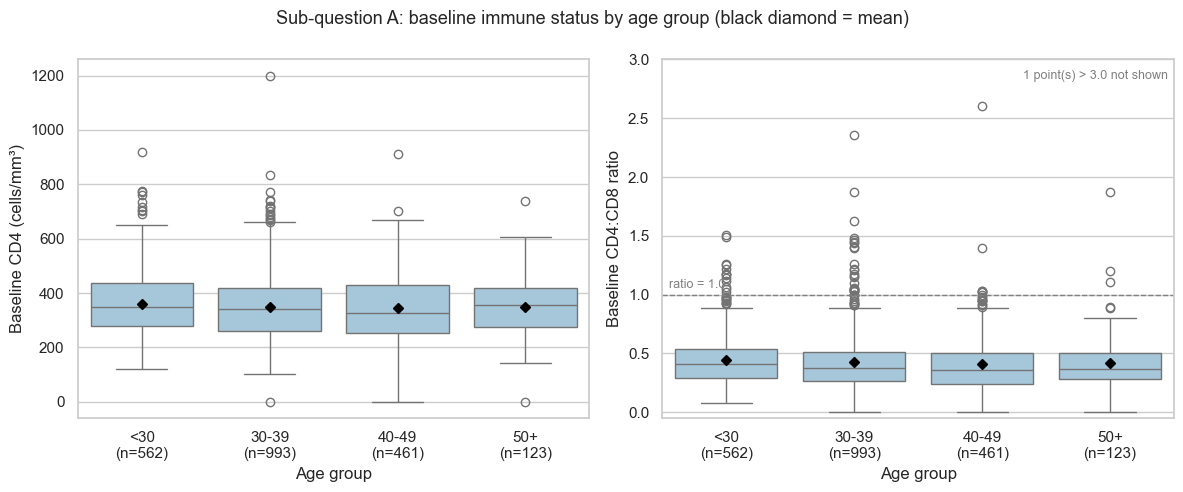

In [4]:
# Visualization 1: baseline CD4 and CD4:CD8 ratio by age bracket, with n annotated
n_by_group = df["age_group"].value_counts().reindex(AGE_LABELS)
tick_labels = [f"{g}\n(n={n})" for g, n in n_by_group.items()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [("cd40", "Baseline CD4 (cells/mm³)"),
          ("cd4_cd8_ratio", "Baseline CD4:CD8 ratio")]
for ax, (col, ylabel) in zip(axes, panels):
    sns.boxplot(data=df, x="age_group", y=col, ax=ax, color="#9ecae1",
                showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "black",
                           "markeredgecolor": "black", "markersize": 5})
    ax.set_xticks(range(len(AGE_LABELS)))
    ax.set_xticklabels(tick_labels)
    ax.set_xlabel("Age group")
    ax.set_ylabel(ylabel)
axes[1].axhline(1.0, ls="--", color="grey", lw=1)
axes[1].text(-0.45, 1.03, "ratio = 1.0", ha="left", va="bottom", color="grey", fontsize=9)
# A single extreme ratio (10.0) flattens the boxes, so cap the y-axis and say what is hidden
RATIO_CAP = 3.0
n_hidden = (df["cd4_cd8_ratio"] > RATIO_CAP).sum()
axes[1].set_ylim(-0.05, RATIO_CAP)
axes[1].text(3.45, RATIO_CAP * 0.97, f"{n_hidden} point(s) > {RATIO_CAP} not shown",
             ha="right", va="top", fontsize=9, color="grey")
fig.suptitle("Sub-question A: baseline immune status by age group (black diamond = mean)", fontsize=13)
fig.tight_layout()
plt.show()

In [5]:
# Group summaries
summary_A = (df.groupby("age_group", observed=True)[["cd40", "cd4_cd8_ratio"]]
               .agg(["count", "mean", "median", "std"]).round(2))
display(summary_A)

# Age as categorical: one-way ANOVA across brackets
# Age as continuous: simple regression (slope reported per 10 years)
rows = []
for col in ["cd40", "cd4_cd8_ratio"]:
    anova_p = anova_lm(smf.ols(f"{col} ~ C(age_group)", data=df).fit())["PR(>F)"].iloc[0]
    m = smf.ols(f"{col} ~ age", data=df).fit()
    lo, hi = m.conf_int().loc["age"] * 10
    rows.append({"outcome": col,
                 "ANOVA p (brackets)": anova_p,
                 "slope per 10 yrs": m.params["age"] * 10,
                 "95% CI low": lo, "95% CI high": hi,
                 "slope p": m.pvalues["age"],
                 "R²": m.rsquared})
results_A = pd.DataFrame(rows).set_index("outcome")
results_A.style.format("{:.4f}")

cd40                        cd4_cd8_ratio                   
          count    mean median     std         count  mean median   std
age_group                                                              
<30         562  360.78  350.0  119.60           562  0.44   0.41  0.21
30-39       993  347.77  341.0  118.29           993  0.43   0.38  0.38
40-49       461  344.22  326.0  119.37           461  0.41   0.36  0.23
50+         123  349.14  356.0  111.46           123  0.42   0.37  0.24

,ANOVA p (brackets),slope per 10 yrs,95% CI low,95% CI high,slope p,R²
outcome,,,,,,
cd40,0.1084,-5.4871,-11.2582,0.2840,0.0624,0.0016
cd4_cd8_ratio,0.3917,-0.0171,-0.0320,-0.0022,0.0244,0.0024


## 3. Primary question + Sub-question B: CD4 change, age, and treatment

Model (OLS, full data, HC3 robust standard errors):

`cd4_change ~ cd40 + age_c * C(trt_label, Treatment('ZDV'))`

- The `trt` main effects are each arm's CD4 gain vs. ZDV alone **at the mean age**.
- The `age_c:trt` interaction terms show how that gain shifts per year of age. These terms answer Sub-question B.
- An F-test against the main-effects-only model tests all three interaction terms together.
- Drop-one ΔR² shows how much variance each predictor explains on its own, after accounting for the others.

In [6]:
TRT_TERM = "C(trt_label, Treatment('ZDV'))"
f_main = f"cd4_change ~ cd40 + age_c + {TRT_TERM}"
f_int  = f"cd4_change ~ cd40 + age_c * {TRT_TERM}"

m_main = smf.ols(f_main, data=df).fit(cov_type="HC3")
m_int  = smf.ols(f_int,  data=df).fit(cov_type="HC3")
print(m_int.summary())

                            OLS Regression Results                            
Dep. Variable:             cd4_change   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     29.98
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           9.47e-45
Time:                        13:41:36   Log-Likelihood:                -13173.
No. Observations:                2139   AIC:                         2.636e+04
Df Residuals:                    2130   BIC:                         2.642e+04
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                                                        coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

In [7]:
# Does age change the treatment effect? Joint test of the 3 interaction terms
int_terms = [p for p in m_int.params.index if ":" in p]
joint = m_int.wald_test(" = 0, ".join(int_terms) + " = 0", use_f=True, scalar=True)
print(f"Joint Wald test of age x trt interaction: F = {joint.statistic:.2f}, "
      f"df = {len(int_terms)}, p = {joint.pvalue:.4f}")

# How much does each predictor contribute? Drop-one change in R² (main-effects model)
full_r2 = smf.ols(f_main, data=df).fit().rsquared
contrib = {
    "cd40 (baseline CD4)": full_r2 - smf.ols(f"cd4_change ~ age_c + {TRT_TERM}", data=df).fit().rsquared,
    "age": full_r2 - smf.ols(f"cd4_change ~ cd40 + {TRT_TERM}", data=df).fit().rsquared,
    "treatment arm": full_r2 - smf.ols("cd4_change ~ cd40 + age_c", data=df).fit().rsquared,
}
print(f"\nMain-effects model R² = {full_r2:.3f}")
print("Unique R² contribution (drop-one ΔR²):")
for k, v in contrib.items():
    print(f"  {k:<22} {v:.4f}")

# Treatment effects vs ZDV at mean age, per-decade age slope
nice = lambda s: s.replace(f"{TRT_TERM}[T.", "").replace("]", "")
main_tbl = pd.DataFrame({"coef": m_main.params, "ci_low": m_main.conf_int()[0],
                         "ci_high": m_main.conf_int()[1], "p": m_main.pvalues})
main_tbl.index = [nice(i) for i in main_tbl.index]
main_tbl.loc["age_c (per 10 yrs)"] = main_tbl.loc["age_c", ["coef", "ci_low", "ci_high"]].mul(10).tolist() + [main_tbl.loc["age_c", "p"]]
main_tbl.round(4)

Joint Wald test of age x trt interaction: F = 3.60, df = 3, p = 0.0130

Main-effects model R² = 0.120
Unique R² contribution (drop-one ΔR²):
  cd40 (baseline CD4)    0.0767
  age                    0.0006
  treatment arm          0.0413


,coef,ci_low,ci_high,p
Intercept,83.9602,64.0442,103.8763,0.0000
ZDV + ddI,70.2338,55.7454,84.7222,0.0000
ZDV + Zal,36.2764,23.7470,48.8059,0.0000
ddI,42.2444,29.5320,54.9567,0.0000
cd40,-0.2860,-0.3397,-0.2324,0.0000
age_c,-0.3418,-0.8887,0.2051,0.2206
age_c (per 10 yrs),-3.4182,-8.8869,2.0505,0.2206


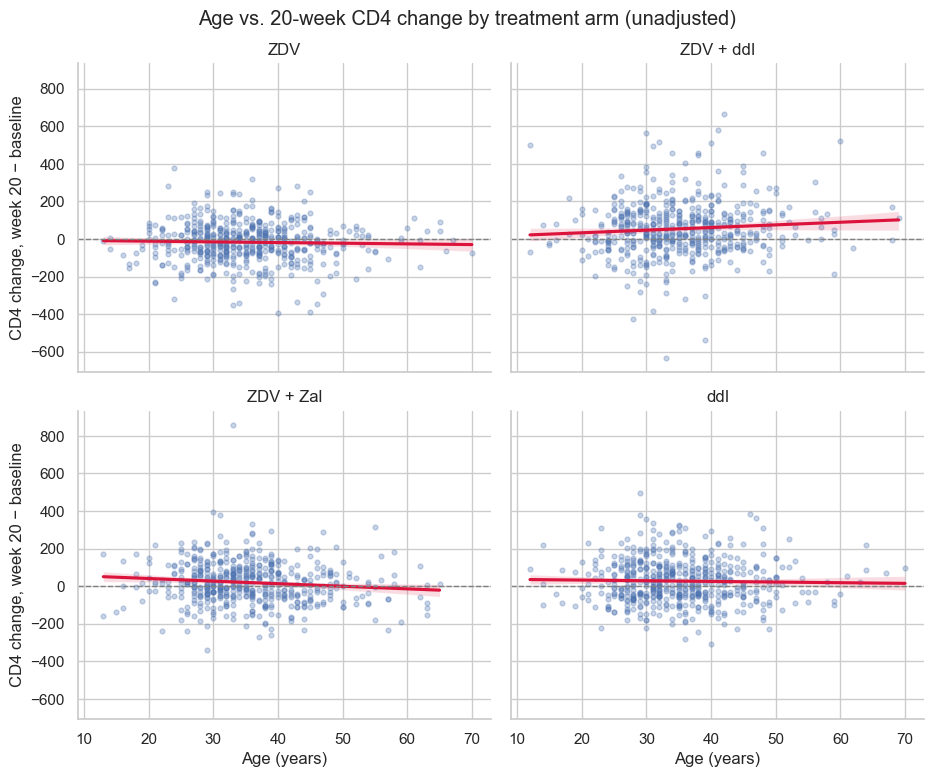

In [8]:
# Visualization 2a: age vs CD4 change, one panel per arm (NOT adjusted for cd40)
g = sns.lmplot(data=df, x="age", y="cd4_change", col="trt_label", col_order=TRT_ORDER,
               col_wrap=2, height=3.8, aspect=1.25,
               scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "crimson"})
for ax in g.axes.flat:
    ax.axhline(0, color="grey", lw=1, ls="--")
g.set_titles("{col_name}")
g.set_axis_labels("Age (years)", "CD4 change, week 20 − baseline")
g.figure.suptitle("Age vs. 20-week CD4 change by treatment arm (unadjusted)", y=1.02)
plt.show()

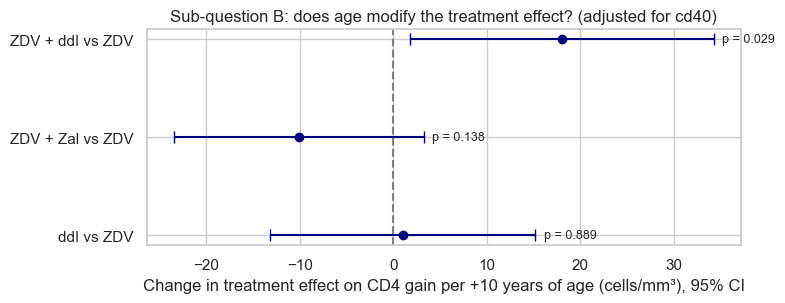

,term,coef,low,high,p
0,ZDV + ddI vs ZDV,18.066,1.827,34.305,0.029
1,ZDV + Zal vs ZDV,-10.125,-23.496,3.247,0.138
2,ddI vs ZDV,1.008,-13.181,15.198,0.889


In [9]:
# Visualization 2b: forest plot of age x trt interaction coefficients (adjusted for cd40)
ci = m_int.conf_int()
forest = pd.DataFrame({
    "term": [nice(t).replace("age_c:", "") + " vs ZDV" for t in int_terms],
    "coef": m_int.params[int_terms].values * 10,   # per 10 years of age
    "low":  ci.loc[int_terms, 0].values * 10,
    "high": ci.loc[int_terms, 1].values * 10,
    "p":    m_int.pvalues[int_terms].values,
})

fig, ax = plt.subplots(figsize=(8, 3.2))
ypos = np.arange(len(forest))[::-1]
ax.errorbar(forest["coef"], ypos,
            xerr=[forest["coef"] - forest["low"], forest["high"] - forest["coef"]],
            fmt="o", color="navy", ecolor="navy", capsize=4)
ax.axvline(0, color="grey", ls="--")
ax.set_yticks(ypos)
ax.set_yticklabels(forest["term"])
for yi, (_, r) in zip(ypos, forest.iterrows()):
    ax.annotate(f"p = {r.p:.3f}", (r.high, yi), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9)
ax.set_xlabel("Change in treatment effect on CD4 gain per +10 years of age (cells/mm³), 95% CI")
ax.set_title("Sub-question B: does age modify the treatment effect? (adjusted for cd40)")
fig.tight_layout()
plt.show()
forest.round(3)

## 4. Predictive check: how well do we predict CD4 change? (Visualization 3)

The model is refit on an 80% training split and evaluated **on the held-out 20% only**. The target is `cd4_change` rather than `cd420`. Predicting `cd420` looks better only because it tracks `cd40`, and the comparison below shows how much.

Test R² (cd4_change): 0.101 | RMSE: 119.9 cells/mm³
Test R² (cd420, same predictors): 0.364  <- inflated by tracking cd40


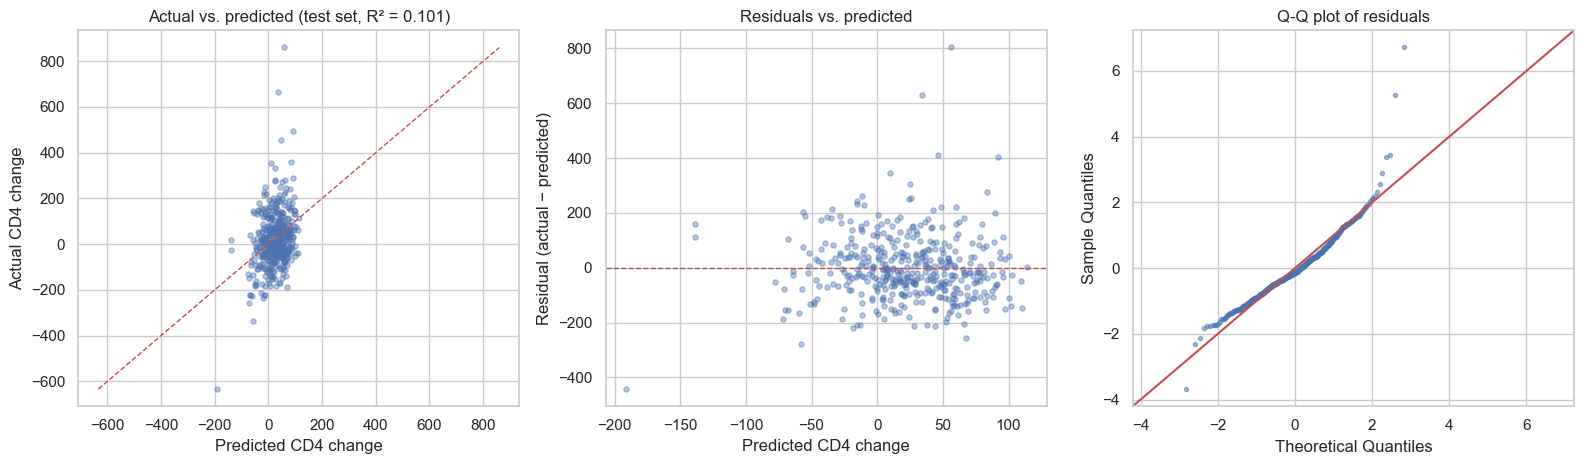

In [10]:
train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE,
                               stratify=df["trt_label"])
m_pred = smf.ols(f_int, data=train).fit()
pred = m_pred.predict(test)
resid = test["cd4_change"] - pred

r2_change = r2_score(test["cd4_change"], pred)
rmse = np.sqrt(mean_squared_error(test["cd4_change"], pred))

# For comparison only: the same predictors, but predicting cd420 directly
m_420 = smf.ols(f_int.replace("cd4_change", "cd420"), data=train).fit()
r2_420 = r2_score(test["cd420"], m_420.predict(test))

print(f"Test R² (cd4_change): {r2_change:.3f} | RMSE: {rmse:.1f} cells/mm³")
print(f"Test R² (cd420, same predictors): {r2_420:.3f}  <- inflated by tracking cd40")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
ax.scatter(pred, test["cd4_change"], alpha=0.4, s=14)
lims = [min(pred.min(), test["cd4_change"].min()), max(pred.max(), test["cd4_change"].max())]
ax.plot(lims, lims, "r--", lw=1)
ax.set(xlabel="Predicted CD4 change", ylabel="Actual CD4 change",
       title=f"Actual vs. predicted (test set, R² = {r2_change:.3f})")

ax = axes[1]
ax.scatter(pred, resid, alpha=0.4, s=14)
ax.axhline(0, color="r", ls="--", lw=1)
ax.set(xlabel="Predicted CD4 change", ylabel="Residual (actual − predicted)",
       title="Residuals vs. predicted")

sm.qqplot(resid, line="45", fit=True, ax=axes[2], markersize=3, alpha=0.5)
axes[2].set_title("Q-Q plot of residuals")
fig.tight_layout()
plt.show()

## 5. Sub-question C: predicting clinical failure (`cid`)

Logistic regression with a stratified 80/20 split, comparing three nested feature sets:

1. **Age + treatment**
2. **+ baseline CD4** (`cd40`)
3. **+ early CD4 change** (`cd4_change`)

Comparing models 2 and 3 isolates what the 20-week change adds beyond where the patient started.

Excluded on purpose:
- `time` is days until the event, so it leaks the answer.
- `treat` duplicates `trt`.

Caveat: `cd4_change` uses the week-20 count, and 13 of the 521 failures occur before day 140. Model 3 therefore uses information from slightly after those few events.

In [11]:
print(f"Failures with time < 140 days: {((df.cid == 1) & (df.time < 140)).sum()} of {df.cid.sum()}")

trt_dummies = pd.get_dummies(df["trt_label"], prefix="trt", drop_first=True, dtype=float)  # ZDV = reference
Xc = pd.concat([df[["age", "cd40", "cd4_change"]], trt_dummies], axis=1)
yc = df["cid"]
TRT_COLS = list(trt_dummies.columns)

feature_sets = {
    "Age + treatment": ["age"] + TRT_COLS,
    "+ baseline CD4": ["age"] + TRT_COLS + ["cd40"],
    "+ early CD4 change": ["age"] + TRT_COLS + ["cd40", "cd4_change"],
}

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2,
                                              random_state=RANDOM_STATE, stratify=yc)
clf_results = {}
for name, cols in feature_sets.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    clf.fit(Xc_tr[cols], yc_tr)
    proba = clf.predict_proba(Xc_te[cols])[:, 1]
    clf_results[name] = {"model": clf, "cols": cols, "proba": proba,
                         "auc": roc_auc_score(yc_te, proba)}
    print(f"{name:<22} test ROC-AUC = {clf_results[name]['auc']:.3f}")

Failures with time < 140 days: 13 of 521
Age + treatment        test ROC-AUC = 0.609
+ baseline CD4         test ROC-AUC = 0.681
+ early CD4 change     test ROC-AUC = 0.758


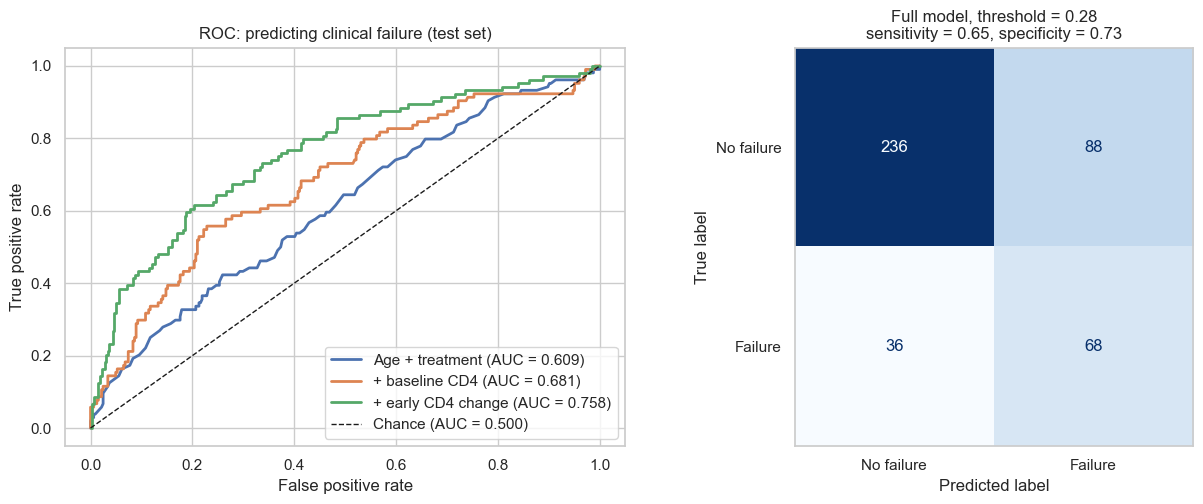

In [12]:
# Visualization 4a: ROC curves (test set) + confusion matrix for the full model
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
for name, r in clf_results.items():
    fpr, tpr, _ = roc_curve(yc_te, r["proba"])
    ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {r['auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.500)")
ax.set(xlabel="False positive rate", ylabel="True positive rate",
       title="ROC: predicting clinical failure (test set)")
ax.legend(loc="lower right")

# Threshold chosen on TRAINING data (Youden's J) so the test set stays untouched
full = clf_results["+ early CD4 change"]
tr_proba = full["model"].predict_proba(Xc_tr[full["cols"]])[:, 1]
fpr_tr, tpr_tr, thr_tr = roc_curve(yc_tr, tr_proba)
threshold = thr_tr[np.argmax(tpr_tr - fpr_tr)]
y_hat = (full["proba"] >= threshold).astype(int)
cm = confusion_matrix(yc_te, y_hat)
ConfusionMatrixDisplay(cm, display_labels=["No failure", "Failure"]).plot(
    ax=axes[1], cmap="Blues", colorbar=False)
axes[1].grid(False)
tn, fp, fn, tp = cm.ravel()
axes[1].set_title(f"Full model, threshold = {threshold:.2f}\n"
                  f"sensitivity = {tp/(tp+fn):.2f}, specificity = {tn/(tn+fp):.2f}")
fig.tight_layout()
plt.show()

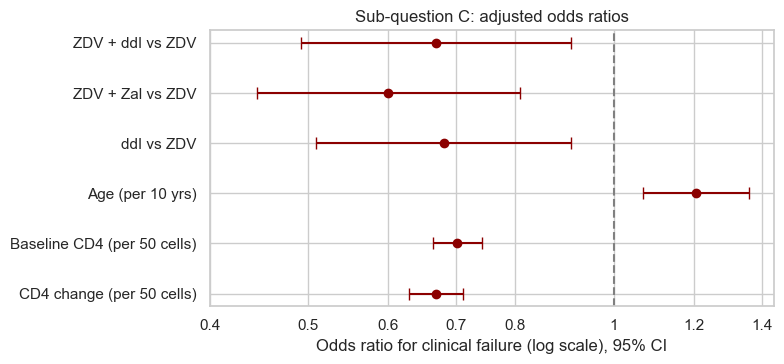

,OR,low,high,p
ZDV + ddI vs ZDV,0.668,0.492,0.907,0.010
ZDV + Zal vs ZDV,0.600,0.445,0.808,0.001
ddI vs ZDV,0.680,0.510,0.908,0.009
Age (per 10 yrs),1.205,1.068,1.360,0.002
Baseline CD4 (per 50 cells),0.701,0.663,0.742,0.000
CD4 change (per 50 cells),0.668,0.628,0.710,0.000


In [13]:
# Visualization 4b: odds-ratio forest plot (statsmodels Logit on full data, interpretable units)
logit_df = df.assign(age_10=df["age"] / 10, cd40_50=df["cd40"] / 50,
                     cd4_change_50=df["cd4_change"] / 50)
m_logit = smf.logit(f"cid ~ age_10 + {TRT_TERM} + cd40_50 + cd4_change_50",
                    data=logit_df).fit(disp=0)
or_tbl = pd.DataFrame({"OR": np.exp(m_logit.params),
                       "low": np.exp(m_logit.conf_int()[0]),
                       "high": np.exp(m_logit.conf_int()[1]),
                       "p": m_logit.pvalues}).drop("Intercept")
or_tbl.index = (pd.Index([nice(i) for i in or_tbl.index])
                .str.replace("age_10", "Age (per 10 yrs)")
                .str.replace("cd40_50", "Baseline CD4 (per 50 cells)")
                .str.replace("cd4_change_50", "CD4 change (per 50 cells)"))
or_tbl.index = [i if i.startswith(("Age", "Baseline", "CD4")) else f"{i} vs ZDV" for i in or_tbl.index]

fig, ax = plt.subplots(figsize=(8, 3.8))
ypos = np.arange(len(or_tbl))[::-1]
ax.errorbar(or_tbl["OR"], ypos,
            xerr=[or_tbl["OR"] - or_tbl["low"], or_tbl["high"] - or_tbl["OR"]],
            fmt="o", color="darkred", capsize=4)
ax.axvline(1, color="grey", ls="--")
ax.set_xscale("log")
OR_TICKS = [0.4, 0.5, 0.6, 0.7, 0.8, 1.0, 1.2, 1.4]
ax.set_xticks(OR_TICKS)
ax.set_xticklabels([f"{t:g}" for t in OR_TICKS])
ax.minorticks_off()
ax.set_yticks(ypos)
ax.set_yticklabels(or_tbl.index)
ax.set_xlabel("Odds ratio for clinical failure (log scale), 95% CI")
ax.set_title("Sub-question C: adjusted odds ratios")
fig.tight_layout()
plt.show()
or_tbl.round(3)

## 6. Findings

_Numbers come from the run with `RANDOM_STATE = 42`. The train/test metrics (R², AUC) will shift slightly with a different split._

**Sub-question A (baseline status).** Age has at most a weak relationship with baseline immune status.
- Mean `cd40` is between 344 and 361 cells/mm³ in every age bracket (ANOVA p ≈ 0.11).
- As a continuous predictor, each extra 10 years of age goes with about 5.5 fewer CD4 cells (95% CI −11.3 to +0.3, p ≈ 0.06).
- The CD4:CD8 ratio drops about 0.017 per decade (p ≈ 0.02). That is statistically detectable but clinically negligible, and the bracket ANOVA is not significant (p ≈ 0.39).
- This weak pattern is consistent with the trial's enrollment rule of CD4 between 200 and 500. Every age group's median ratio is well below 1.0, which reflects HIV-driven immune dysregulation regardless of age.

**Primary question (contributions to CD4 change).** The main-effects model explains about 12% of the variance in 20-week CD4 change.
- **Baseline CD4 contributes the most** (unique ΔR² ≈ 0.077). Each extra baseline cell predicts about 0.29 fewer cells of gain, which looks like regression to the mean.
- **Treatment arm comes next** (ΔR² ≈ 0.041). Compared with ZDV alone, at mean age:
  - ZDV + ddI gains about +70 cells (95% CI 56 to 85)
  - ddI alone gains about +42 cells
  - ZDV + Zal gains about +36 cells
  - All three p < 0.001.
- **Age on its own contributes almost nothing** (ΔR² ≈ 0.001; −3.4 cells per decade, p ≈ 0.22).

**Sub-question B (age × treatment).** Age does modify the treatment effect (joint Wald F = 3.60 on 3 df, p ≈ 0.013). The modification comes mainly from **ZDV + ddI**: its advantage over ZDV grows by about 18 cells per 10 years of age (95% CI 1.8 to 34, p ≈ 0.03). The ZDV + Zal and ddI-alone interactions are not significant. This is one significant term out of three, with a wide CI and only 123 patients aged 50+. Treat it as a hypothesis to confirm, not an established result.

**Predictive check (Visualization 3).**
- Held-out R² for `cd4_change` is about 0.10. The same predictors reach R² ≈ 0.36 for `cd420`, but only because `cd420` tracks `cd40`.
- Residuals are right-skewed with heavy tails (see the Q-Q plot). The HC3 robust standard errors are used for that reason.

**Sub-question C (clinical failure).** Test ROC-AUC by feature set:
- Age + treatment: **0.61**
- Adding baseline CD4: **0.68**
- Adding 20-week CD4 change: **0.76**

So early CD4 change adds substantial predictive value beyond age, treatment and baseline CD4. In the adjusted logistic model:
- Each +50 cells of CD4 change lowers the odds of failure by about a third (OR ≈ 0.67).
- Each 10 years of age raises the odds by about 20% (OR ≈ 1.21).
- All three non-ZDV arms have about 32–40% lower odds than ZDV alone.